##### Installing packages

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy
from scipy import stats
import arviz as az
# os.environ["PATH"] += os.pathsep + r'C:\Users\user\Downloads\windows_10_msbuild_Release_graphviz-7.1.0-win32\Graphviz\bin'

### Regression model

In [57]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-darkgrid')

<ipython-input-57-3750e48f4523>:4: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-darkgrid')


### In this part wish to do prediction using Bayesian linear regression

In [ ]:
# Initialize random number generator
np.random.seed(123)

# True parameter values
alpha, sigma = 1, 1
beta = [1, 2.5]

# Size of dataset
size = 100

# Predictor variable
X1 = np.random.randn(size)
X2 = np.random.randn(size) * 0.2

# Simulate outcome variable
Y = alpha + beta[0]*X1 + beta[1]*X2 + np.random.randn(size)*sigma

### X1 and X2 and the explantory varibles and we wish to predict y

### The y data histrogram looks like this.


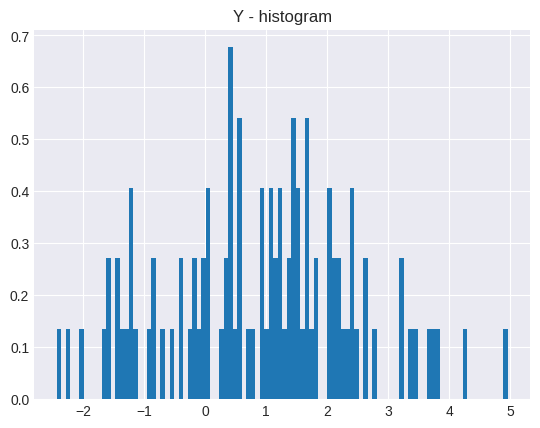

In [ ]:
plt.figure()
plt.hist(Y, density = True, bins = 100)
plt.title('Y - histogram')
plt.show()

### Visualising X1 and X2 against Y

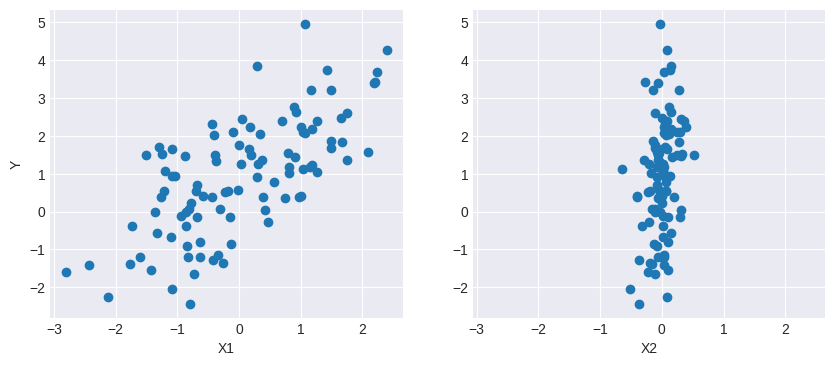

In [ ]:
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(10,4))
axes[0].scatter(X1, Y)
axes[1].scatter(X2, Y)
axes[0].set_ylabel('Y'); axes[0].set_xlabel('X1'); axes[1].set_xlabel('X2');

In [ ]:
with pm.Model() as basic_model:

    # Priors for unknown model parameters
    alpha = pm.Normal('alpha', mu=0, sigma=100)
    beta = pm.Normal('beta', mu=0, sigma=100, shape=2)
    sigma = pm.HalfNormal('sigma', sigma=100)

    # Expected value of outcome
    mu = pm.Deterministic(alpha + beta[0]*X1 + beta[1]*X2)
    priors_samples = pm.sample_prior_predictive(samples=200, random_seed=35)

    # Likelihood (sampling distribution) of observations
    Y_obs = pm.Normal('Y_obs', mu=mu, sigma=sigma, observed=Y)

    trace = pm.sample(5000)

#### HalfNormal distribution

In [ ]:
priors_samples.prior['sigma'].shape

(1, 200)

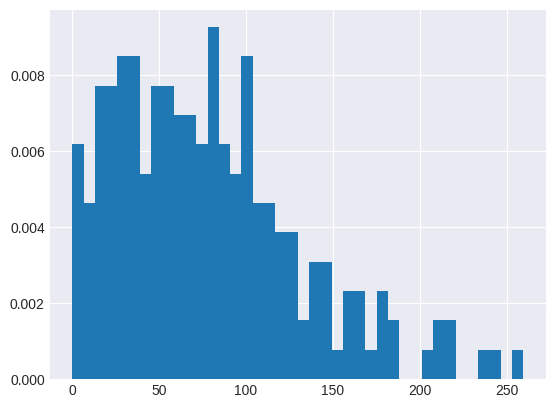

In [ ]:
plt.figure()
plt.hist(np.array(priors_samples.prior['sigma']).flatten(), density = True, bins = 40)
plt.show()

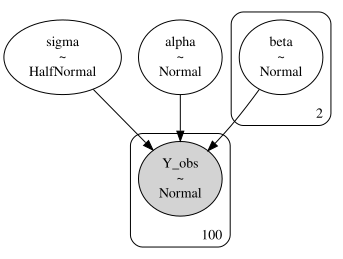

In [ ]:
pm.model_to_graphviz(basic_model)

In [ ]:
with basic_model:
    # draw 5000 posterior samples
    trace = pm.sample(5000)

/usr/local/lib/python3.10/dist-packages/arviz/utils.py:184: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  numba_fn = numba.jit(**self.kwargs)(self.function)


array([[<Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'beta'}>,
        <Axes: title={'center': 'beta'}>],
       [<Axes: title={'center': 'sigma'}>,
        <Axes: title={'center': 'sigma'}>]], dtype=object)

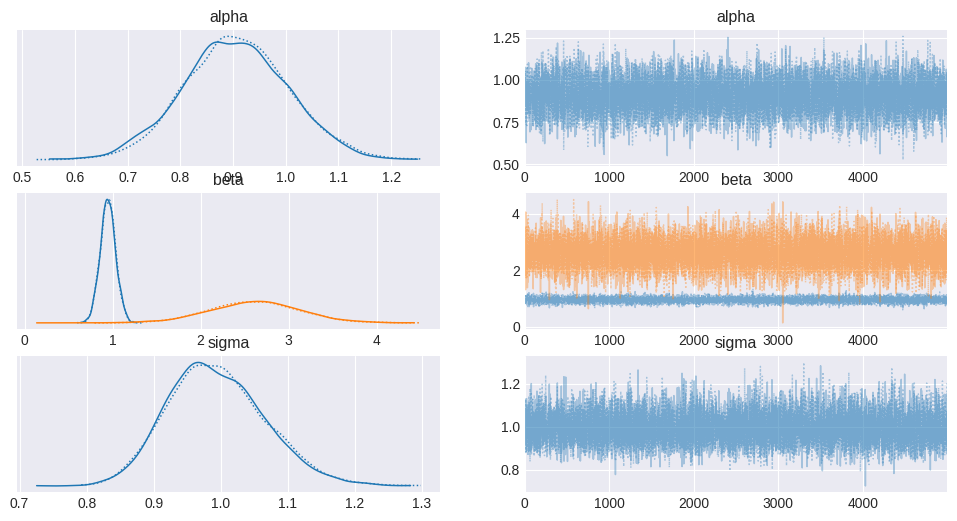

In [ ]:
az.plot_trace(trace)

In [ ]:
pm.summary(trace).round(2)

/usr/local/lib/python3.10/dist-packages/arviz/utils.py:184: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  numba_fn = numba.jit(**self.kwargs)(self.function)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,0.91,0.10,0.72,1.09,0.0,0.0,11046.0,7840.0,1.0
beta[0],0.95,0.09,0.78,1.11,0.0,0.0,14309.0,8498.0,1.0
beta[1],2.62,0.51,1.65,3.56,0.0,0.0,14186.0,7987.0,1.0
sigma,0.99,0.07,0.86,1.13,0.0,0.0,13368.0,8048.0,1.0


 The table above provide suggested values of the regression parameters and their uncertainty. For example, the value of alpha 94% credible interval is between 0.95 to 1.06. The total interval lenght is 0.11. Weather or not it is conisdered a large interval depands on the context and in most cases in life is clear.  

# Evaluating Hypotheses with Bayes

Statistical inference is a process of learning from incomplete or imperfect (error-contaminated) data. Can account for this "imperfection" using either a sampling model or a measurement error model.

### Statistical hypothesis testing

The *de facto* standard for statistical inference is statistical hypothesis testing. The goal of hypothesis testing is to evaluate a **null hypothesis**. There are two possible outcomes:

- reject the null hypothesis
- fail to reject the null hypothesis

Rejection occurs when a chosen test statistic is higher than some pre-specified threshold valuel; non-rejection occurs otherwise.

Notice that neither outcome says anything about the quantity of interest, the **research hypothesis**.

Setting up a statistical test involves several subjective choices by the user that are rarely justified based on the problem or decision at hand:

- statistical test to use
- null hypothesis to test
- significance level

Choices are often based on arbitrary criteria, including "statistical tradition" (Johnson 1999). The resulting evidence is indirect, incomplete, and typically overstates the evidence against the null hypothesis (Goodman 1999).

Most importantly to applied users, the results of statistical hypothesis tests are very easy to misinterpret.

### Estimation

Instead of testing, a more informative and effective approach for inference is based on **estimation** (be it frequentist or Bayesian). That is, rather than testing whether two groups are different, we instead pursue an estimate of *how different* they are, which is fundamentally more informative.

Additionally, we include an estimate of **uncertainty** associated with that difference which includes uncertainty due to our lack of knowledge of the model parameters (*epistemic uncertainty*) and uncertainty due to the inherent stochasticity of the system (*aleatory uncertainty*).

## One Group

Before we compare two groups using Bayesian analysis, let's start with an even simpler scenario: statistical inference for one group.

For this we will use Gelman et al.'s (2007) radon dataset. In this dataset the amount of the radioactive gas radon has been measured among different households in all counties of several states. Radon gas is known to be the highest cause of lung cancer in non-smokers. It is believed to be more strongly present in households containing a basement and to differ in amount present among types of soil.

>  the US EPA has set an action level of 4 pCi/L. At or above this level of radon, the EPA recommends you take corrective measures to reduce your exposure to radon gas.

![radon](images/how_radon_enters.jpg)

Let's import the dataset:

In [ ]:
import pandas as pd
import seaborn as sns
# sns.set_context('coreotebook')

RANDOM_SEED = 20090425

In [ ]:
colab = True

if colab:

   from google.colab import drive
   drive.mount('/content/drive')
   radon = pd.read_csv("/content/drive/My Drive/Bayesian_programming/lesson1/data/radon.csv")
else:
   radon = pd.read_csv('../data/radon.csv', index_col=0)

Mounted at /content/drive


In [ ]:
radon.head(5)

,Unnamed: 0,idnum,state,state2,stfips,zip,region,typebldg,floor,room,...,pcterr,adjwt,dupflag,zipflag,cntyfips,county,fips,Uppm,county_code,log_radon
0,0,5081.0,MN,MN,27.0,55735,5.0,1.0,1.0,3.0,...,9.7,1146.499190,1.0,0.0,1.0,AITKIN,27001.0,0.502054,0,0.832909
1,1,5082.0,MN,MN,27.0,55748,5.0,1.0,0.0,4.0,...,14.5,471.366223,0.0,0.0,1.0,AITKIN,27001.0,0.502054,0,0.832909
2,2,5083.0,MN,MN,27.0,55748,5.0,1.0,0.0,4.0,...,9.6,433.316718,0.0,0.0,1.0,AITKIN,27001.0,0.502054,0,1.098612
3,3,5084.0,MN,MN,27.0,56469,5.0,1.0,0.0,4.0,...,24.3,461.623670,0.0,0.0,1.0,AITKIN,27001.0,0.502054,0,0.095310
4,4,5085.0,MN,MN,27.0,55011,3.0,1.0,0.0,4.0,...,13.8,433.316718,0.0,0.0,3.0,ANOKA,27003.0,0.428565,1,1.163151


Let's focus on the (log) radon levels measured in a single county (Hennepin).

Suppose we are interested in:

- whether the mean radon value is greater than 4 pCi/L in Hennepin county
- the probability that any randomly-chosen household in Hennepin county has a reading of greater than 4

In [ ]:
np.log(4)

1.3862943611198906

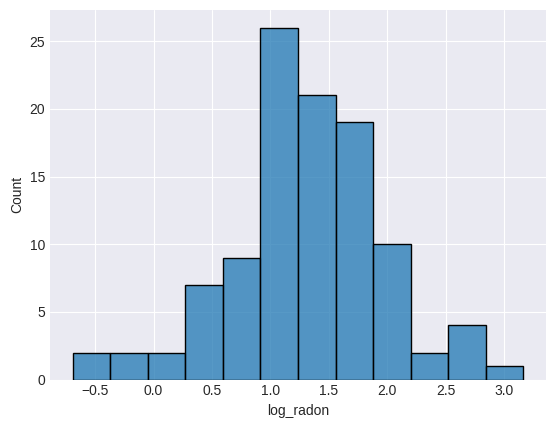

In [ ]:
hennepin_radon = radon.query('county=="HENNEPIN"').log_radon
sns.histplot(radon.loc[radon['county']=='HENNEPIN', 'log_radon']);

### The model

Recall that the first step in Bayesian inference is specifying a **full probability model** for the problem.

This consists of:

- a likelihood function(s) for the observations
- priors for all unknown quantities

The measurements look approximately normal, so let's start by assuming a normal distribution as the sampling distribution (likelihood) for the data.

$$y_i \sim N(\mu, \sigma^2)$$

(don't worry, we can evaluate this assumption)

This implies that we have 2 unknowns in the model; the mean and standard deviation of the distribution.

#### Prior choice

How do we choose distributions to use as priors for these parameters?

There are several considerations:

- discrete vs continuous values
- the support of the variable
- the available prior information

While there may likely be prior information about the distribution of radon values, we will assume no prior knowledge, and specify a **diffuse** prior for each parameter.

Since the mean can take any real value (since it is on the log scale), we will use another normal distribution here, and specify a large variance to allow the possibility of very large or very small values:

$$\mu \sim N(0, 10^2)$$

For the standard deviation, we know that the true value must be positive (no negative variances!). I will choose a uniform prior bounded from below at zero and from above at a value that is sure to be higher than any plausible value the true standard deviation (on the log scale) could take.

$$\sigma \sim U(0, 10)$$

We can encode these in a Python model, using the PyMC package, as follows:

In [ ]:
# from pymc import Model, Normal, Uniform, Exponential

with pm.Model() as radon_model:

    μ = pm.Normal('μ', mu=0, sigma=10)
    σ = pm.Uniform('σ', 0, 10)

> ## Software
> Today there is an array of software choices for Bayesians, including both open source software (*e.g.*, Stan, PyMC, Pyro, TensorFlow Probability) and commercial (*e.g.*, SAS, Stata). These examples can be replicated in any of these environments.

All that remains is to add the likelihood, which takes $\mu$ and $\sigma$ as parameters, and the log-radon values as the set of observations:

In [ ]:
with radon_model:

    dist = pm.Normal('dist', mu=μ, sigma=σ, observed=hennepin_radon)
    dist1 = pm.Normal('dist1', mu=μ, sigma=σ)

Before we go ahead and estimate the model paramters from the data, it's a good idea to perform a **prior predictive check**. This involves sampling from the model before data are incorporated, and gives you an idea of the range of observations that would be considered reasonable within the scope of the modeling assumptions (including choice of priors). If the simnulations generate too many extreme observations relative to our expectations based on domain knowledge, then it can be an indication of problems with model formulation.

In [ ]:

with radon_model:

    prior_sample = pm.sample_prior_predictive(1000)

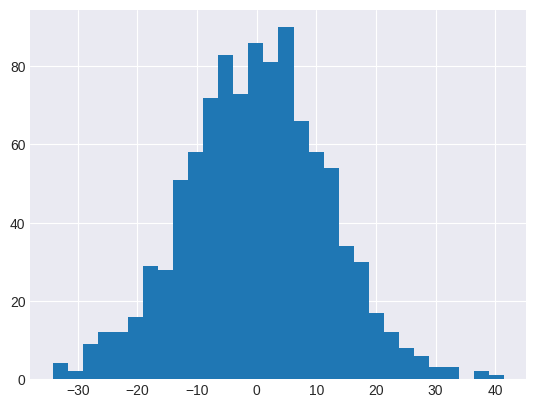

In [ ]:
plt.hist(np.array(prior_sample.prior['dist1']).flatten(), bins=30);

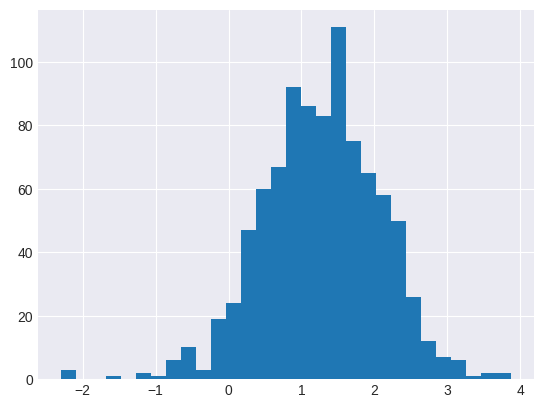

In [ ]:
# The true values
plt.hist(radon.log_radon, bins=30);

Now, we will fit the model using **Markov chain Monte Carlo (MCMC)**, which will be covered in detail in an upcoming section. This will draw samples from the posterior distribution (which cannot be calculated exactly).

In [ ]:

with radon_model:

    samples = pm.sample(1000, tune=1000,  random_seed=RANDOM_SEED)

In [ ]:
np.log(4)

1.3862943611198906

In [ ]:
mus = np.array(samples.posterior['μ']).flatten()
1-mus[mus<np.log(4)].shape[0]/mus.shape[0]

0.16749999999999998

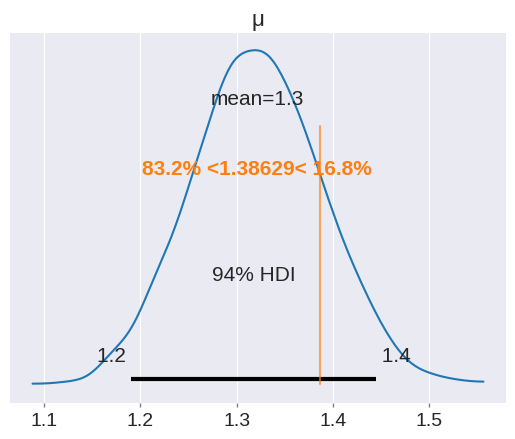

In [ ]:
from arviz import plot_posterior

plot_posterior(samples, var_names=['μ'], ref_val=np.log(4),  kind='kde');

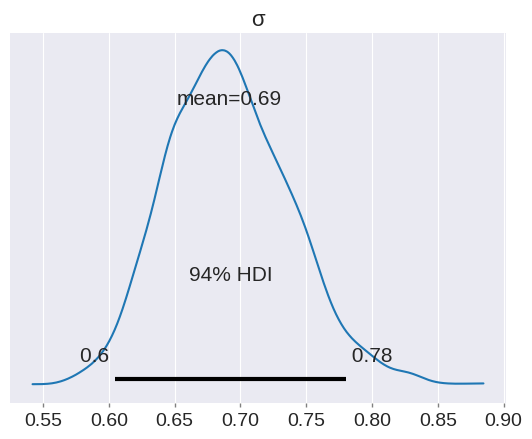

In [ ]:
plot_posterior(samples, var_names=['σ'],   kind='kde');

The plot shows the posterior distribution of $\mu$, along with an estimate of the 94% posterior **credible interval**.

The output

    82.8% < 1.38629 < 17.2%
    
informs us that the probability of $\mu$ being less than log(4) is 82.8% and the corresponding probability of being greater than log(4) is 17.2%.

> The posterior probability that the mean level of household radon in Henneprin County is greater than 4 pCi/L is 0.172.

### Prediction

What is the probability that a given household has a log-radon measurement larger than 1.38? To answer this, we make use of the **posterior predictive distribution**.

$$p(z |y) = \int_{\theta} p(z |\theta) p(\theta | y) d\theta$$

where here $z$ is the predicted value and y is the data used to fit the model.

We can estimate this from the posterior samples of the parameters in the model.

In [ ]:
mus = np.array(samples.posterior['μ']).flatten()
sigmas = np.array(samples.posterior['σ']).flatten()

In [ ]:
radon_samples = np.random.normal(mus, sigmas)

In [ ]:
(radon_samples > np.log(4)).mean()

0.458

## We can try use sample_posterior_predictive to compute the same thing

In [ ]:
with radon_model:
    pm.sample_posterior_predictive(samples, extend_inferencedata=True)


posterior = np.array(samples.posterior_predictive.dist).flatten()

(posterior > np.log(4)).mean()

0.4639857142857143

We got more or a less the same result

> The posterior probability that a randomly-selected household in Henneprin County contains radon levels in excess of 4 pCi/L is about 0.47.

### Model checking

But, ***how do we know this model is any good?***

Its important to check the fit of the model, to see if its assumptions are reasonable. One way to do this is to perform **posterior predictive checks**. This involves generating simulated data using the model that you built, and comparing that data to the observed data.

One can choose a particular statistic to compare, such as tail probabilities or quartiles, but here it is useful to compare them graphically.

We already have these simulations from the previous exercise!

<Axes: xlabel='dist / dist'>

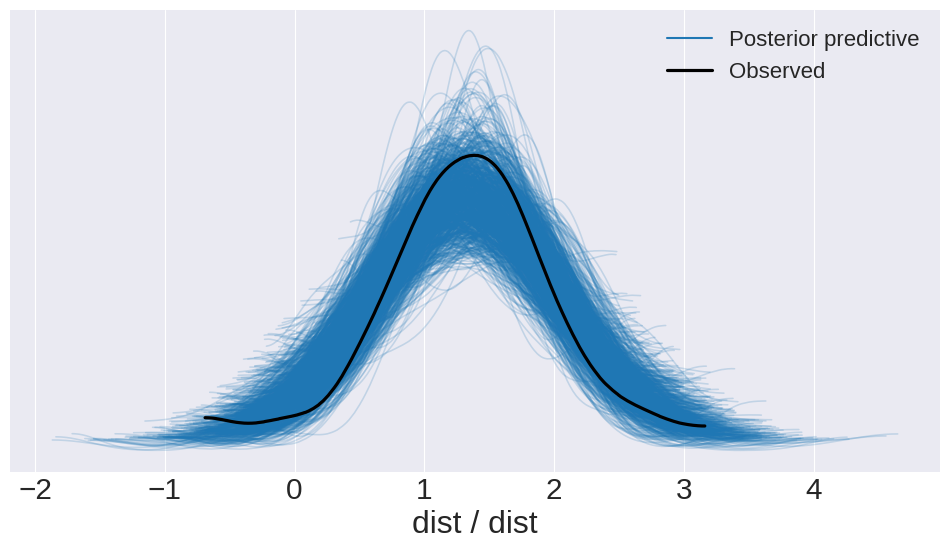

In [ ]:
with radon_model:
    pm.sample_posterior_predictive(samples, extend_inferencedata=True)
az.plot_ppc(samples, figsize=(12, 6), mean=False, num_pp_samples=1000)


## Two Groups with Continuous Outcome

To illustrate how this Bayesian estimation approach works in practice, we will use a fictitious example from Kruschke (2012) concerning the evaluation of a clinical trial for drug evaluation. The trial aims to evaluate the efficiancy of a "smart drug" that is supposed to increase intelligence by comparing IQ scores of individuals in a treatment arm (those receiving the drug) to those in a control arm (those recieving a placebo). There are 47 individuals and 42 individuals in the treatment and control arms, respectively.

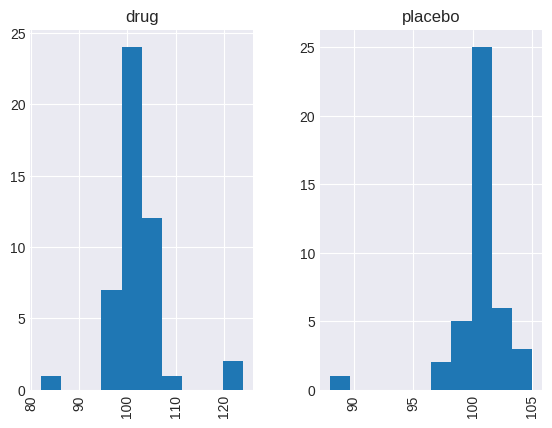

In [58]:
drug = pd.DataFrame(dict(iq=(101,100,102,104,102,97,105,105,98,101,100,123,105,103,100,95,102,106,
        109,102,82,102,100,102,102,101,102,102,103,103,97,97,103,101,97,104,
        96,103,124,101,101,100,101,101,104,100,101),
                         group='drug'))
placebo = pd.DataFrame(dict(iq=(99,101,100,101,102,100,97,101,104,101,102,102,100,105,88,101,100,
           104,100,100,100,101,102,103,97,101,101,100,101,99,101,100,100,
           101,100,99,101,100,102,99,100,99),
                            group='placebo'))

n1 = drug.shape[0]
n2 = placebo.shape[0]

trial_data = pd.concat([drug, placebo], ignore_index=True)
trial_data.hist('iq', by='group');

Since there appear to be extreme ("outlier") values in the data, we will choose a Student-t distribution to describe the distributions of the scores in each group. This sampling distribution adds **robustness** to the analysis, as a T distribution is less sensitive to outlier observations, relative to a normal distribution.

The three-parameter Student-t distribution allows for the specification of a mean $\mu$, a precision (inverse-variance) $\lambda$ and a degrees-of-freedom parameter $\nu$:

$$f(x|\mu,\lambda,\nu) = \frac{\Gamma(\frac{\nu + 1}{2})}{\Gamma(\frac{\nu}{2})} \left(\frac{\lambda}{\pi\nu}\right)^{\frac{1}{2}} \left[1+\frac{\lambda(x-\mu)^2}{\nu}\right]^{-\frac{\nu+1}{2}}$$
           
the degrees-of-freedom parameter essentially specifies the "normality" of the data, since larger values of $\nu$ make the distribution converge to a normal distribution, while small values (close to zero) result in heavier tails.

Thus, the likelihood functions of our model are specified as follows:

$$\begin{align}
y^{(drug)}_i &\sim T(\nu, \mu_1, \sigma_1) \\
y^{(placebo)}_i &\sim T(\nu, \mu_2, \sigma_2)
\end{align}$$

As a simplifying assumption, we will assume that the degree of normality $\nu$ is the same for both groups.

### Prior choice

Since the means are real-valued, we will apply normal priors. Since we know something about the population distribution of IQ values, we will center the priors at 100, and use a standard deviation that is more than wide enough to account for plausible deviations from this population mean:

$$\mu_k \sim N(100, 10^2)$$

In [ ]:
with pm.Model() as drug_model:

    μ_0 = pm.Normal('μ_0', 100, sigma=10)
    μ_1 = pm.Normal('μ_1', 100, sigma=10)

Similarly, we will use a uniform prior for the standard deviations, with an upper bound of 20.

In [ ]:
with drug_model:
    σ_0 = pm.Uniform('σ_0', lower=0, upper=20)
    σ_1 = pm.Uniform('σ_1', lower=0, upper=20)

For the degrees-of-freedom parameter $\nu$, we will use an **exponential** distribution with a mean of 30; this allocates high prior probability over the regions of the parameter that describe the range from normal to heavy-tailed data under the Student-T distribution.

In [ ]:


with drug_model:
    ν = pm.Exponential('ν', 1/30.)


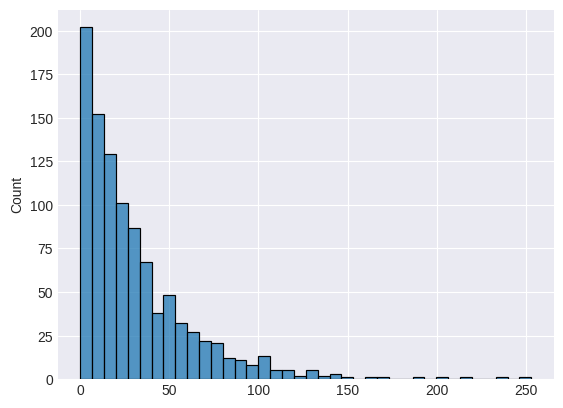

In [ ]:
x = pm.Exponential.dist(1/30)
x_draws = pm.draw(x, draws=1000, random_seed=1)
sns.histplot(x_draws);

In [ ]:
with drug_model:

    drug_like = pm.StudentT('drug_like', nu=ν, mu=μ_1, sigma=σ_1, observed=drug.iq)
    placebo_like = pm.StudentT('placebo_like', nu=ν, mu=μ_0, sigma=σ_0, observed=placebo.iq)

Now that the model is fully specified, we can turn our attention to tracking the posterior quantities of interest. Namely, we can calculate the difference in means between the drug and placebo groups.

As a joint measure of the groups, we will also estimate the "effect size", which is the difference in means scaled by the pooled estimates of standard deviation. This quantity can be harder to interpret, since it is no longer in the same units as our data, but it is a function of all four estimated parameters.

### Effect size is another word for Cohen's d

In [ ]:

with drug_model:
    ## Deterministic function
    diff_of_means = pm.Deterministic('difference of means', μ_1 - μ_0)
    effect_size = pm.Deterministic('effect size', diff_of_means / np.sqrt(((n1-1)*σ_1**2 + (n2-1)*σ_0**2) / (n1+n2-2)))


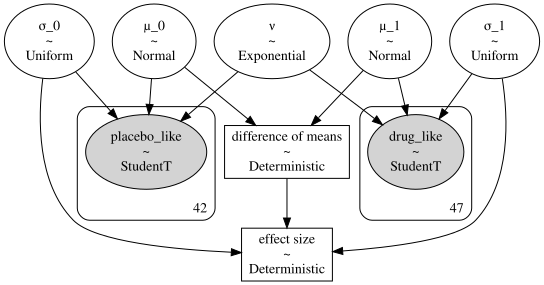

In [ ]:
pm.model_to_graphviz(drug_model)

In [ ]:
with drug_model:

    drug_trace = pm.sample(10000, random_seed=RANDOM_SEED)

In [ ]:
drug_trace.posterior

<xarray.Dataset>
Dimensions:              (chain: 2, draw: 10000)
Coordinates:
  * chain                (chain) int64 0 1
  * draw                 (draw) int64 0 1 2 3 4 5 ... 9995 9996 9997 9998 9999
Data variables:
    μ_0                  (chain, draw) float64 100.5 100.4 100.2 ... 100.6 100.4
    μ_1                  (chain, draw) float64 101.6 102.3 101.0 ... 101.3 102.0
    σ_0                  (chain, draw) float64 1.053 1.079 ... 0.9587 1.222
    σ_1                  (chain, draw) float64 2.468 2.547 2.825 ... 1.483 2.273
    ν_minus_one          (chain, draw) float64 1.377 0.8137 ... 0.6192 1.573
    difference of means  (chain, draw) float64 1.04 1.878 ... 0.7346 1.523
    effect size          (chain, draw) float64 0.5378 0.9416 ... 0.5814 0.8213
Attributes:
    created_at:                 2024-05-16T07:19:57.305210
    arviz_version:              0.15.1
    inference_library:          pymc
    inference_library_version:  5.10.4
    sampling_time:              53.613184690475464
    tuning_steps:               1000

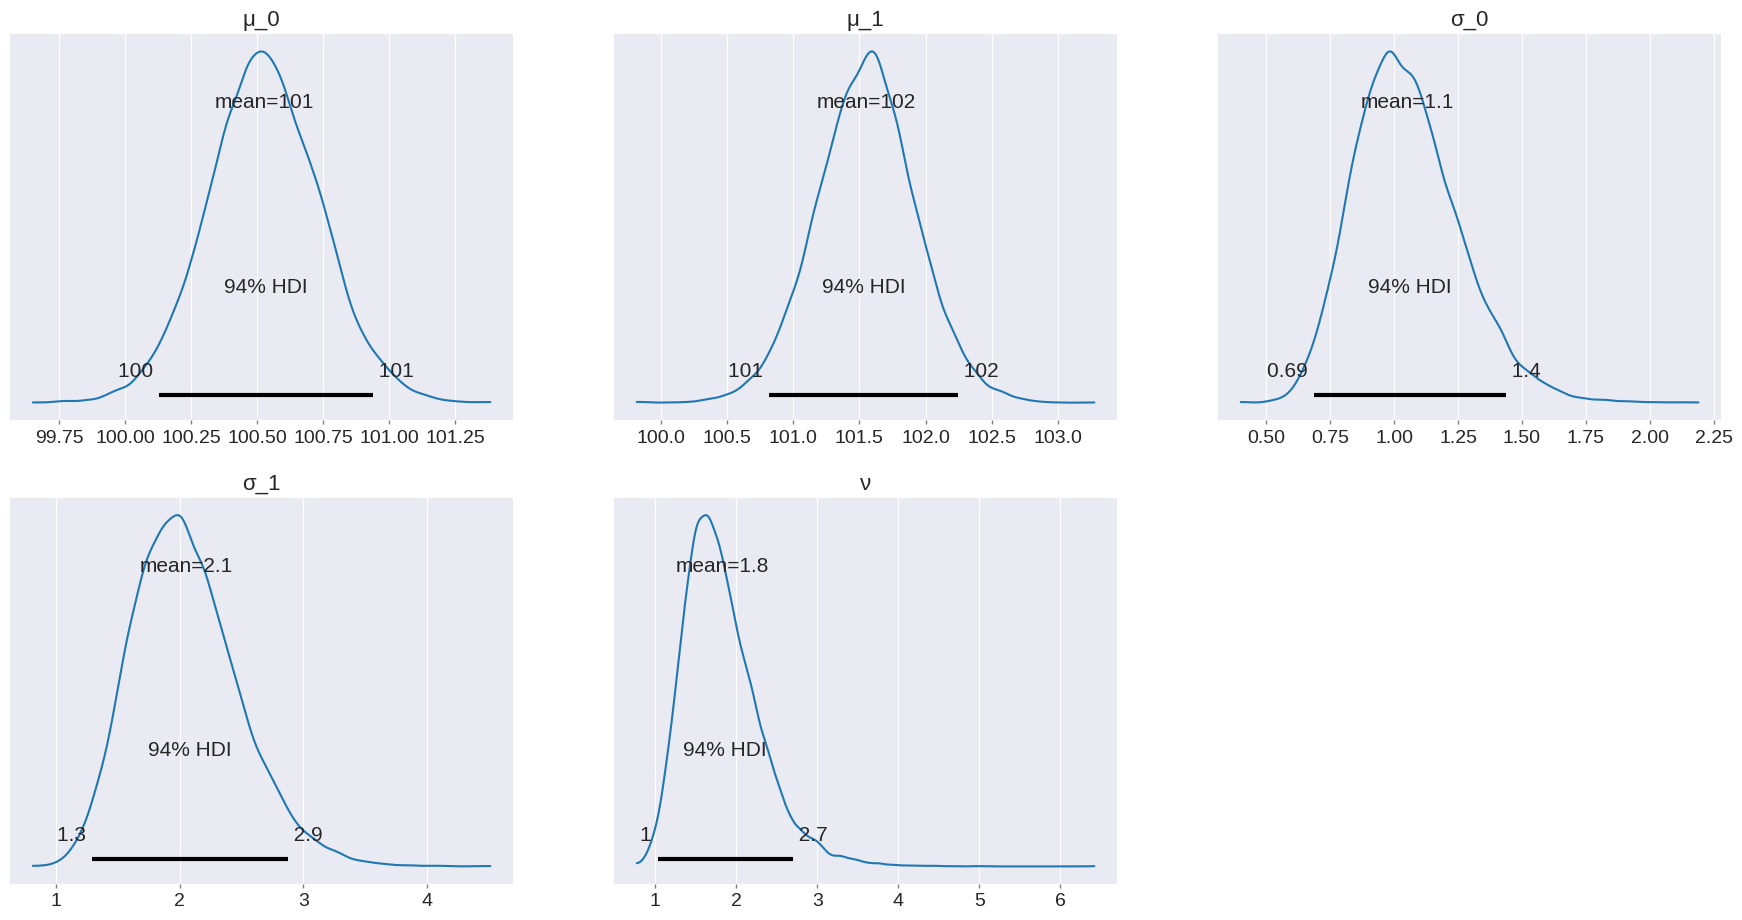

In [ ]:
az.plot_posterior(drug_trace, var_names=['μ_0', 'μ_1', 'σ_0', 'σ_1', 'ν']);

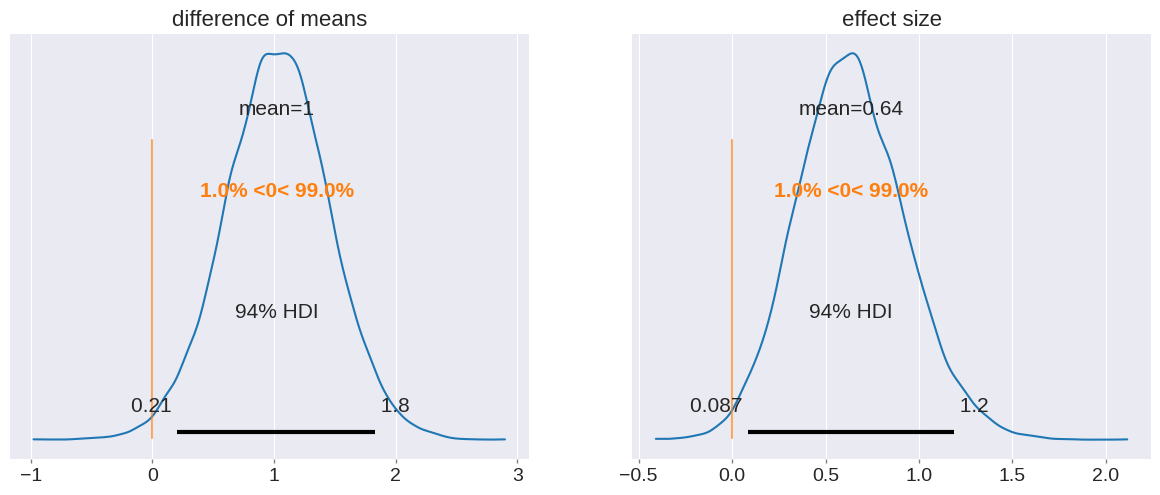

In [ ]:
az.plot_posterior(drug_trace,
          var_names=['difference of means', 'effect size'],
          ref_val=0);

> The posterior probability that the mean IQ of subjects in the treatment group is greater than that of the control group is 0.99.

### Lets have a look if we see what happens when the priot of ν is uniform instead of exponential:

In [63]:
with pm.Model() as drug_model1:

    μ_0 = pm.Normal('μ_0', 100, sigma=10)
    μ_1 = pm.Normal('μ_1', 100, sigma=10)

    σ_0 = pm.Uniform('σ_0', lower=0, upper=20)
    σ_1 = pm.Uniform('σ_1', lower=0, upper=20)

    ν = pm.Uniform('ν', 0, 30)

    drug_like = pm.StudentT('drug_like', nu=ν, mu=μ_1, sigma=σ_1, observed=drug.iq)
    placebo_like = pm.StudentT('placebo_like', nu=ν, mu=μ_0, sigma=σ_0, observed=placebo.iq)

    diff_of_means = pm.Deterministic('difference of means', μ_1 - μ_0)
    effect_size = pm.Deterministic('effect size', diff_of_means / np.sqrt(((n1-1)*σ_1**2 + (n2-1)*σ_0**2) / (n1+n2-2)))

    drug_trace1 = pm.sample(10000, random_seed=RANDOM_SEED)


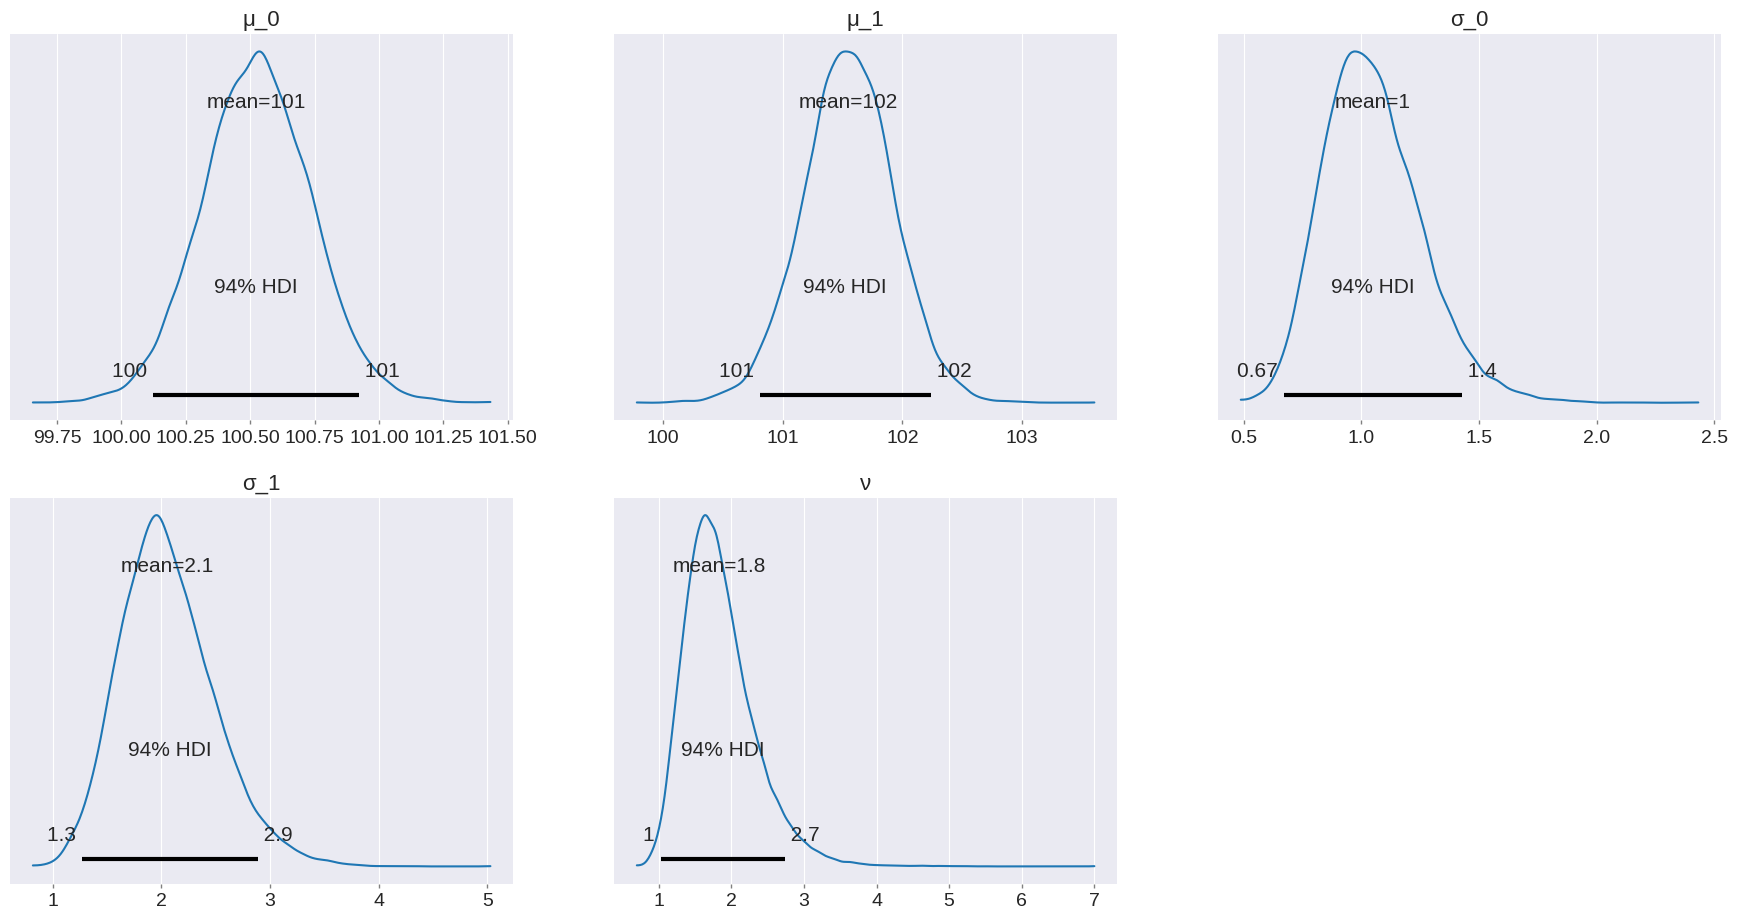

In [64]:
az.plot_posterior(drug_trace1, var_names=['μ_0', 'μ_1', 'σ_0', 'σ_1', 'ν']);

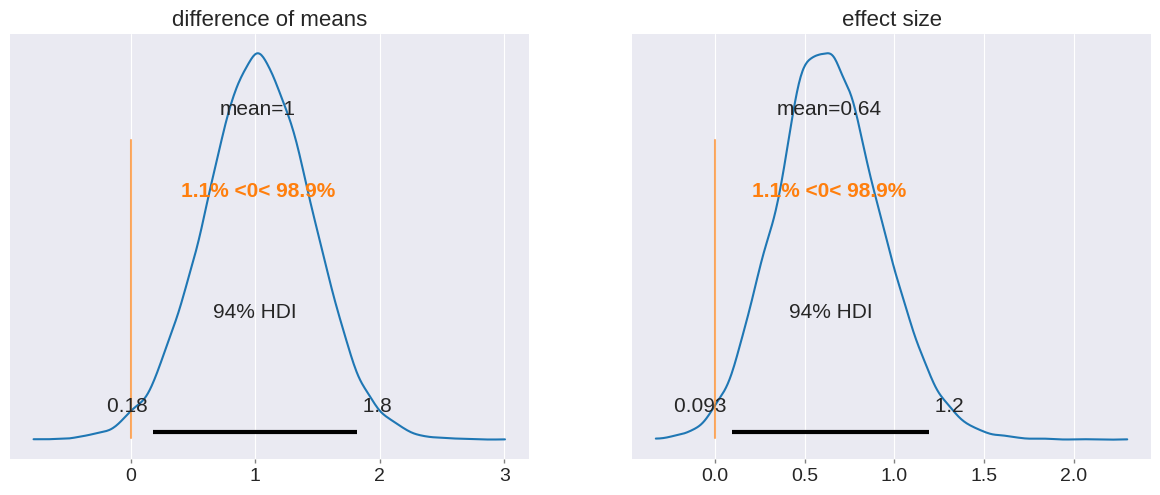

In [65]:
az.plot_posterior(drug_trace1,
          var_names=['difference of means', 'effect size'],
          ref_val=0);

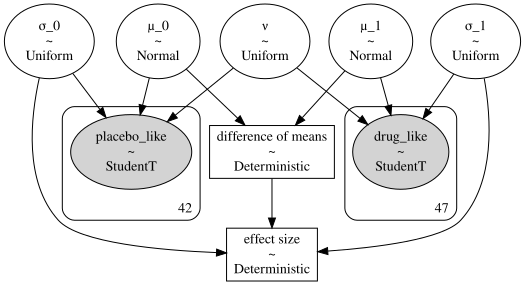

In [66]:
pm.model_to_graphviz(drug_model1)

### Looks like we have similar results here.